# Using pyCRLD in a distributional framework

## Imports

In [1]:
from pyCRLD.Agents.StrategyActorCritic import stratAC
from pyCRLD.Environments.EcologicalPublicGood import EcologicalPublicGood
from pyCRLD.Utils import FlowPlot as fp

import numpy as np
import itertools as it
import matplotlib.pyplot as plt
from scipy.stats import norm
from pyCRLD.Utils.Helpers import compute_stationarydistribution

from datetime import datetime

## Environment

In [2]:
# Define environment

env = EcologicalPublicGood(N=2, f=1.2, c=5, m=-4, qc=0.2, qr=0.1, degraded_choice=True)
env

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


EcologicalPublicGood_2_1.2_5_-4_0.2_0.1_DegChoi

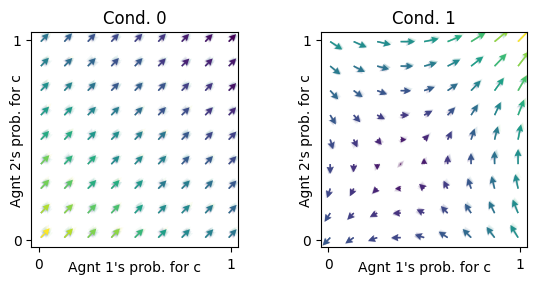

In [3]:
# Init enviornment and MultiAgentEnvironment-interface
mae = stratAC(env=env, learning_rates=0.1, discount_factors=0.9, use_prefactor=True)

x = ([0], [0,1], [0])  # Plotting only the prosperous state
y = ([1], [0,1], [0])  # Plotting only the prosperous state
ax = fp.plot_strategy_flow(mae, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), NrRandom=16)

## A distributional perspective
Discretize rewards into a finate set $\mathcal R = \{r_1, \dots, r_{n_r}\}$


In [4]:
n_r = 8  # number of reward elements

In [5]:
# compute "bins" for reward distributions
def compute_means_and_delta(env, n_r):
    means = np.linspace(env.R.min(), env.R.max(), n_r)
    delta = np.unique((means[1:] - means[:-1]).round(8))
    assert len(delta) == 1
    delta = delta[0]
    return means, delta

# example with given env and number of reward elements
means, delta = compute_means_and_delta(env, n_r) 
print(means)
print(delta)

[-4. -3. -2. -1.  0.  1.  2.  3.]
1.0


In [6]:
# return unique elements of reward tensor
np.unique(env.R)

array([-4., -2.,  0.,  1.,  3.])

In [7]:
# define boundaries for distrib bins
boundaries = np.array(list(means - delta/2) + [means[-1] + delta/2])
boundaries

array([-4.5, -3.5, -2.5, -1.5, -0.5,  0.5,  1.5,  2.5,  3.5])

## Reward distribution

We transfrom the reward function into a reward distribution:

Reward function $R^i(s, \boldsymbol a, s')$

Reward distribution $R^i(s, \boldsymbol a, s', r)$



In [8]:
def compute_Risjasr(env, n_r, sig=0.0):
    means, delta = compute_means_and_delta(env, n_r)
    Risjasr = np.ones(env.R.shape + (n_r,)) * -1  # last dim is distrib
    # print(Risjasr.shape)
        
    if sig==0.0:  # hard
        for r in range(n_r):
            Risjasr[..., r] = (env.R == means[r]).astype(int)
                
    else:  # soft
        sig = sig*delta

        for index, _ in np.ndenumerate(env.R):
            valr = env.R[index]  
            # print(valr)
            for r in range(n_r):
    
                if r==0:
                    prop = norm.cdf(means[r]+delta/2, valr, sig)
                elif r==n_r-1: # last interval
                    prop = 1 - norm.cdf(means[r]-delta/2, valr, sig)
                else:
                    prop = norm.cdf(means[r]+delta/2, valr, sig) - norm.cdf(means[r]-delta/2, valr, sig)   
                Risjasr[index +(r,)] = prop

    return Risjasr

n_r = 21
sig = 0.5
Risjasr = compute_Risjasr(env, n_r, sig)
means, delta = compute_means_and_delta(env, n_r)

The reward, and value strategy-average become the distributions.

## Reward distribution `Risr`

$\bar R^i(s, r) = \sum_{s'}\sum_{a^i}\prod_{j} X^j(s, a^j) T(s, \boldsymbol a, s') R^i(s, \boldsymbol a, s', r)$

In [9]:
def compute_Risr(Xisa, env, n_r, sig=0.0):
    i = 0; s = 1; sprim = 2; r=3; b2d = list(range(4, 4+mae.N))
    Risjasr = compute_Risjasr(env, n_r, sig)
    
    X4einsum = list(it.chain(*zip(Xisa,
                            [[s, b2d[a]] for a in range(mae.N)])))

    args = X4einsum + [env.T, [s]+b2d+[sprim],
                       Risjasr, [i, s]+b2d+[sprim, r], [i, s, r]]

    return np.einsum(*args, optimize=mae.opti)

In [10]:
# Define strategy
Xisa = mae.random_softmax_strategy()
# Xisa = np.zeros((2, 2, 2))
# Xisa[1, 1, 1] = 1
# Xisa[0, 1, 0] = 1
# Xisa[:, 0, :] = 0.5
Xisa

Array([[[0.05656356, 0.94343644],
        [0.9457071 , 0.05429289]],

       [[0.5097279 , 0.4902721 ],
        [0.78075606, 0.21924397]]], dtype=float32)

In [15]:
Xisa[:, 1, 0]

Array([0.9457071 , 0.78075606], dtype=float32)

Text(0.5, 0, 'Reward value')

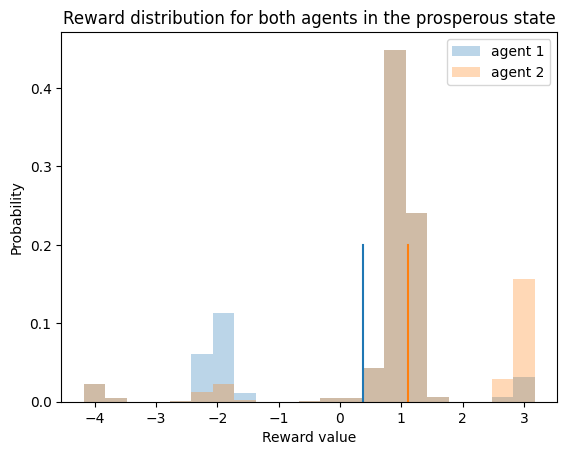

In [12]:
# Plot reward distrib in the prosperous state

# n_r = 8
means, delta = compute_means_and_delta(env, n_r)
Risr = compute_Risr(Xisa, env, n_r, sig)

plt.bar(means, Risr[0,1, :], width=delta, alpha=0.3, label="agent 1")
plt.plot([mae.Ris(Xisa)[0,1],mae.Ris(Xisa)[0,1]],[0, 0.2])

plt.bar(means, Risr[1,1, :], width=delta, alpha=0.3, label="agent 2")
plt.plot([mae.Ris(Xisa)[1,1],mae.Ris(Xisa)[1,1]],[0, 0.2])

plt.legend()

plt.title("Reward distribution for both agents in the prosperous state")

plt.ylabel("Probability")
plt.xlabel("Reward value")

In [16]:
print("error agent 1 prosperous:", np.dot(means, Risr[0, 1, :]) - mae.Ris(Xisa)[0, 1])
print("error agent 2 prosperous:", np.dot(means, Risr[1, 1, :]) - mae.Ris(Xisa)[1, 1])
print("error agent 1 degraded:", np.dot(means, Risr[0, 0, :]) - mae.Ris(Xisa)[0, 0])
print("error agent 2 degraded:", np.dot(means, Risr[1, 0, :]) - mae.Ris(Xisa)[1, 0])

error agent 1 prosperous: -0.0010389686
error agent 2 prosperous: -0.009468913
error agent 1 degraded: 0.0560019
error agent 2 degraded: 0.0560019


## Return distribution $\bar V^i(s, r)$
For $v, r, v' \in \mathcal R$, 

$$ 
V^i(s, v) =  \sum_{r, v', s'} \delta_{vrv'} R^i(s, r) \bar T(s, s') V^i(s', v')
$$

Summarizing

$$M^i(s, v, s', v') = \sum_r \delta(v, r, v') R^i(s, r) \bar T(s, s') $$

yields

$$ 
V^i(s, v) =  \sum_{v', s'} M^i(s, v, s', v') V^i(s', v').
$$

Now we can combine the indices $s \times v = w$ and have $V^i(w) = \sum_{w'} M(w, w') V^i(w')$ to realize that the return distribution should be found in the eigenvalues of the Bellman matrix $M$.

### Smoothed Bellman Kronecker $\delta_{vrv'}$

In [13]:
def compute_bellman_ivrv_(mae, n_r, sig=1.0):
    means, delta = compute_means_and_delta(env, n_r)
    sig = sig*delta

    kron_ivrv_ = np.ones((mae.N, n_r, n_r, n_r)) * -1

    for v in range(n_r):
        for r in range(n_r):
            for v_ in range(n_r):
                
                valv_ = 1/mae.gamma * (means[v] - (1-mae.gamma)*means[r])
                
                # gaussian distribution around valq with std `sig` 
                if v_==0:
                    prop = norm.cdf(means[v_]+delta/2, valv_, sig)
                elif v_==n_r-1: # last intervall
                    prop = 1 - norm.cdf(means[v_]-delta/2, valv_, sig)
                else:
                    prop = norm.cdf(means[v_]+delta/2, valv_, sig) - norm.cdf(means[v_]-delta/2, valv_, sig)
                    
                kron_ivrv_[:,v,r,v_] = prop
    return kron_ivrv_
                
b_ivrv_ = compute_bellman_ivrv_(mae, 19)
assert np.allclose(b_ivrv_.sum(-1), 1.0)

In [17]:
def compute_bellman2_ivrv_(mae, n_r, sig=1.0):
    means, delta = compute_means_and_delta(env, n_r)
    sig = sig*delta

    kron_ivrv_ = np.ones((mae.N, n_r, n_r, n_r)) * -1

    for v in range(n_r):
        for r in range(n_r):
            for v_ in range(n_r):
                
                valv = (1-mae.gamma)*means[r] + mae.gamma*means[v_]
                
                # gaussian distribution around valq with std `sig` 
                if v==0:
                    prop = norm.cdf(means[v]+delta/2, valv, sig)
                elif v==n_r-1: # last intervall
                    prop = 1 - norm.cdf(means[v]-delta/2, valv, sig)
                else:
                    prop = norm.cdf(means[v]+delta/2, valv, sig) - norm.cdf(means[v]-delta/2, valv, sig)
                    
                kron_ivrv_[:,v,r,v_] = prop
    return kron_ivrv_
                
b2_ivrv_ = compute_bellman2_ivrv_(mae, n_r, sig)
assert np.allclose(b2_ivrv_.sum(1), 1.0)

In [14]:
def compute_doublematrix(mae, Xisa, n_r, sig=0.25):
    Tss = mae.Tss(Xisa)
    Risr = compute_Risr(Xisa, mae.env, n_r, sig)
    b_ivrv_ = compute_bellman_ivrv_(mae, n_r, sig)

    i=0; v=1; r=2; v_=3; s=4; s_=5

    M = np.einsum(b_ivrv_, [i,v,r,v_], Risr, [i, s, r], Tss, [s, s_], [i, s, v, s_, v_])
    np.allclose(M.sum((-2,-1)), 1.0)
    return M

M = compute_doublematrix(mae, Xisa, n_r=16)



NameError: name 'compute_bellman_ivrv_' is not defined

In [18]:
def compute_doublematrix2(mae, Xisa, n_r, sig=0.25):
    Tss = mae.Tss(Xisa)
    Risr = compute_Risr(Xisa, mae.env, n_r, sig)
    b2_ivrv_ = compute_bellman2_ivrv_(mae, n_r, sig)

    i=0; v=1; r=2; v_=3; s=4; s_=5

    M = np.einsum(b2_ivrv_, [i,v,r,v_], Risr, [i, s, r], Tss, [s, s_], [i, s, v_, s_, v])
    np.allclose(M.sum((-2,-1)), 1.0)
    return M

M = compute_doublematrix2(mae, Xisa, n_r, sig)
np.allclose(M.sum((-2,-1)), 1.0)

True

In [15]:
def compute_Visr(mae, Xisa, n_r, sig=0.25):
    M = compute_doublematrix(mae, Xisa, n_r, sig)
    Visr = np.ones((mae.N, mae.Z, n_r)) * -1

    for i in range(mae.N):
        mat = M[i].reshape(mae.Z*n_r, mae.Z*n_r)
        _pS = np.array(compute_stationarydistribution(mat))
        _pS = _pS[:, _pS.mean(0)!=-10]
        
        Ps = _pS.reshape(mae.Z, n_r).sum(-1)
        assert np.allclose(mae.Ps(Xisa), Ps, atol=1e-4)

        VIsr = _pS.reshape(mae.Z, n_r) / _pS.reshape(mae.Z, n_r).sum(-1, keepdims=True)

        Visr[i, ...] = VIsr

    return Visr

Visr = compute_Visr(mae, Xisa, n_r, sig)
Visr.sum(-1)

NameError: name 'compute_doublematrix' is not defined

In [19]:
def compute_Visr2(mae, Xisa, n_r, sig=0.25):
    M = compute_doublematrix2(mae, Xisa, n_r, sig)
    Visr = np.ones((mae.N, mae.Z, n_r)) * -1

    for i in range(mae.N):
        mat = M[i].reshape(mae.Z*n_r, mae.Z*n_r)
        _pS = np.array(compute_stationarydistribution(mat))
        _pS = _pS[:, _pS.mean(0)!=-10]
        
        Ps = _pS.reshape(mae.Z, n_r).sum(-1)
        assert np.allclose(mae.Ps(Xisa), Ps, atol=1e-4)

        VIsr = _pS.reshape(mae.Z, n_r) / _pS.reshape(mae.Z, n_r).sum(-1, keepdims=True)

        Visr[i, ...] = VIsr

    return Visr

Visr = compute_Visr2(mae, Xisa, n_r, sig)
Visr.sum(-1)

array([[1.00000004, 1.00000008],
       [1.00000001, 0.99999992]])

In [20]:
print("error agent 1 prosperous:", np.dot(means, Visr[0, 1, :]) - mae.Vis(Xisa)[0, 1])
print("error agent 2 prosperous:", np.dot(means, Visr[1, 1, :]) - mae.Vis(Xisa)[1, 1])
print("error agent 1 degraded:", np.dot(means, Visr[0, 0, :]) - mae.Vis(Xisa)[0, 0])
print("error agent 2 degraded:", np.dot(means, Visr[1, 0, :]) - mae.Vis(Xisa)[1, 0])

error agent 1 prosperous: -0.047417045
error agent 2 prosperous: -0.06739153
error agent 1 degraded: 0.23591232
error agent 2 degraded: 0.24417448


Text(0.5, 0, 'Return value')

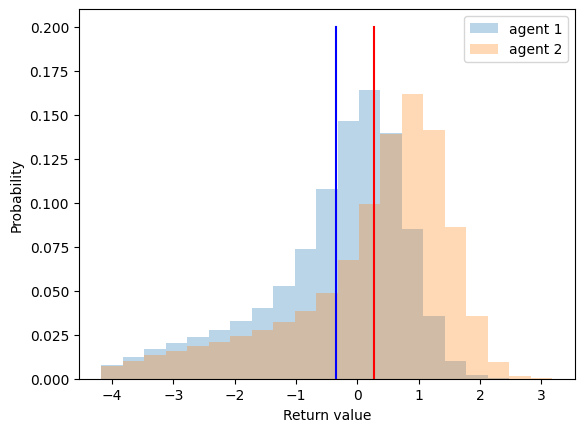

In [21]:
# n_r = 21; sig=0.25
# means, delta = compute_means_and_delta(env, n_r)
Visr = compute_Visr2(mae, Xisa, n_r, sig)

i, s = 1, 1

plt.bar(means, Visr[0,s, :], width=delta, alpha=0.3, label="agent 1")
plt.bar(means, Visr[i,s, :], width=delta, alpha=0.3, label="agent 2")
plt.plot([mae.Vis(Xisa)[0,s], mae.Vis(Xisa)[0,s]], [0, 0.2], c='b')
plt.plot([mae.Vis(Xisa)[i,s], mae.Vis(Xisa)[i,s]], [0, 0.2], c='r')

plt.legend()
plt.ylabel("Probability")
plt.xlabel("Return value")

# Next value $^{next}V^{i}(s, a, v)$

In [22]:
# Compute AC-learning's state-action value (distrib):

def compute_nextVisav(mae, Xisa, n_r, sig=sig):
    means, delta = compute_means_and_delta(env, n_r)
    Visr = compute_Visr2(mae, Xisa, n_r, sig)
    
    i = 0; a = 1; s = 2; s_ = 3; r = 4
    j2k = list(range(6, 6+mae.N-1))  # other agents
    b2d = list(range(6+mae.N-1, 6+mae.N-1 + mae.N))  # all actions
    e2f = list(range(5+2*mae.N, 5+2*mae.N + mae.N-1))  # all other acts

    sumsis = [[j2k[l], s, e2f[l]] for l in range(mae.N-1)]  # sum inds
    otherX = list(it.chain(*zip((mae.N-1)*[Xisa], sumsis)))
                                
    args = [mae.Omega, [i]+j2k+[a]+b2d+e2f] + otherX +\
        [env.T, [s]+b2d+[s_], Visr, [i, s_, r], [i, s, a, r]]

    return np.einsum(*args, optimize=mae.opti)

Text(0.5, 0, 'Q value')

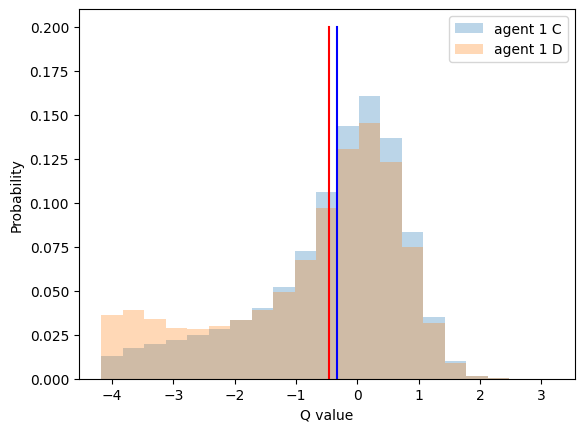

In [23]:
# n_r = 21; sig=0.25
# means, delta = compute_means_and_delta(env, n_r)
nextVisav = compute_nextVisav(mae, Xisa, n_r, sig)

i, s = 1, 1

plt.bar(means, nextVisav[0,s, 0, :], width=delta, alpha=0.3, label="agent 1 C")
plt.bar(means, nextVisav[0,s, 1, :], width=delta, alpha=0.3, label="agent 1 D")
# plt.bar(means, nextVisav[i,s, 0, :], width=delta, alpha=0.3, label="agent 2")
plt.plot([mae.Qisa(Xisa)[0,1,0], mae.Qisa(Xisa)[0,1,0]], [0, 0.2], c='b')
plt.plot([mae.Qisa(Xisa)[0,1,1], mae.Qisa(Xisa)[0,1,1]], [0, 0.2], c='r')

plt.legend()
plt.ylabel("Probability")
plt.xlabel("Q value")

Text(0.5, 0, 'Q value')

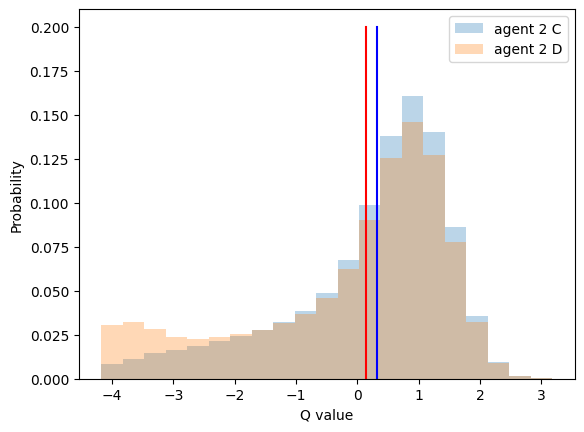

In [24]:
plt.bar(means, nextVisav[1,s, 0, :], width=delta, alpha=0.3, label="agent 2 C")
plt.bar(means, nextVisav[1,s, 1, :], width=delta, alpha=0.3, label="agent 2 D")
# plt.bar(means, nextVisav[i,s, 0, :], width=delta, alpha=0.3, label="agent 2")
plt.plot([mae.Qisa(Xisa)[1,1,0], mae.Qisa(Xisa)[1,1,0]], [0, 0.2], c='b')
plt.plot([mae.Qisa(Xisa)[1,1,1], mae.Qisa(Xisa)[1,1,1]], [0, 0.2], c='r')

plt.legend()
plt.ylabel("Probability")
plt.xlabel("Q value")

In [25]:
nextVisav.sum(-1)

array([[[1.00000004, 1.00000004],
        [1.00000011, 1.00000011]],

       [[1.00000001, 1.00000002],
        [0.99999989, 0.9999999 ]]])

In [26]:
print("error agent 1 prosp coop:", np.dot(means, nextVisav[0, 1, 1, :]) - mae.NextVisa(Xisa)[0, 1, 1])
print("error agent 2 prosp coop:", np.dot(means, nextVisav[1, 1, 1, :]) - mae.NextVisa(Xisa)[1, 1, 1])
print("error agent 1 prosp def:", np.dot(means, nextVisav[0, 1, 0, :]) - mae.NextVisa(Xisa)[0, 1, 0])
print("error agent 2 prosp def:", np.dot(means, nextVisav[1, 1, 0, :]) - mae.NextVisa(Xisa)[1, 1, 0])
print("error agent 1 deg coop:", np.dot(means, nextVisav[0, 0, 1, :]) - mae.NextVisa(Xisa)[0, 0, 1])
print("error agent 2 deg coop:", np.dot(means, nextVisav[1, 0, 1, :]) - mae.NextVisa(Xisa)[1, 0, 1])
print("error agent 1 deg def:", np.dot(means, nextVisav[0, 0, 0, :]) - mae.NextVisa(Xisa)[0, 0, 0])
print("error agent 2 deg def:", np.dot(means, nextVisav[1, 0, 0, :]) - mae.NextVisa(Xisa)[1, 0, 0])

error agent 1 prosp coop: -0.012872279
error agent 2 prosp coop: -0.034543343
error agent 1 prosp def: -0.041205227
error agent 2 prosp def: -0.06569995
error agent 1 deg coop: 0.2286911
error agent 2 deg coop: 0.24329329
error agent 1 deg def: 0.21452451
error agent 2 deg def: 0.22771502


# Prediction error $^{ac}D^{i}(s,a,d)$

In [24]:
def compute_Risar(mae, Xisa, n_r, sig=sig):
    i = 0; a = 1; s = 2; s_ = 3; r = 4  # Variables
    j2k = list(range(5, 5+mae.N-1))  # other agents
    b2d = list(range(5+mae.N-1, 5+mae.N-1 + mae.N))  # all actions
    e2f = list(range(4+2*mae.N, 4+2*mae.N + mae.N-1))  # all other acts
    Risjasr = compute_Risjasr(env, n_r, sig)
 
    sumsis = [[j2k[l], s, e2f[l]] for l in range(mae.N-1)]  # sum inds
    otherX = list(it.chain(*zip((mae.N-1)*[Xisa], sumsis)))

    args = [mae.Omega, [i]+j2k+[a]+b2d+e2f] + otherX\
        + [mae.T, [s]+b2d+[s_], Risjasr, [i, s]+b2d+[s_, r],
            [i, s, a, r]]
    return np.einsum(*args, optimize=mae.opti)

def compute_Disad(mae, Xisa, n_r, sig=sig):
    # Compute needed tensors
    Risar = compute_Risar(mae, Xisa, n_r, sig)
    Visr = compute_Visr2(mae, Xisa, n_r, sig)
    # Reformat Visr
    Visr_x2 = np.zeros((2, 2, 2, n_r))
    Visr_x2[:, :, 0, :] = Visr
    Visr_x2[:, :, 1, :] = Visr
    nextVisav = compute_nextVisav(mae, Xisa, n_r, sig)
    # define new bins, bounds and means for RPEs
    new_means = np.linspace(means.min() - means.max(), means.max() - means.min(), n_r)
    new_delta = np.unique((new_means[1:] - new_means[:-1]).round(8))
    new_bounds = new_means+new_delta/2
    # new_bounds = np.linspace(np.min(dmat) - new_bin/2, np.max(dmat)+new_bin/2, n_r+1)
    Disad = np.zeros((2, 2, 2, n_r))
    for r in range(n_r):
        for v_ in range(n_r):
            for v in range(n_r):
                # compute possible RPE value
                vald = (1 - mae.gamma[0]) * means[r] + mae.gamma[0] * means[v_] - means[v]
                P_d = Risar[:, :, :, r]*nextVisav[:, :, :, v_]*Visr_x2[:, :, :, v]
                d = int(np.sum(vald>new_bounds))
                Disad[:, :, :, d] += P_d         
    return Disad

In [25]:
## Attempt with smoothed Bellman Kronecker delta

def compute_bellman_idvrv_(mae, n_r, sig=1.0):
    means, delta = compute_means_and_delta(env, n_r)
    new_means = np.linspace(means.min() - means.max(), means.max() - means.min(), n_r)
    new_delta = np.unique((new_means[1:] - new_means[:-1]).round(8))
    sig = sig*new_delta

    kron_idvrv_ = np.ones((mae.N, n_r, n_r, n_r, n_r)) * -1

    for d in range(n_r):
        for v in range(n_r):
            for r in range(n_r):
                for v_ in range(n_r):
                
                    vald = (1-mae.gamma)*means[r] + mae.gamma*means[v_] - means[v] 
                
                    # gaussian distribution around valq with std `sig` 
                    if d==0:
                        prop = norm.cdf(new_means[d]+new_delta/2, vald, sig)
                    elif d==n_r-1: # last intervall
                        prop = 1 - norm.cdf(new_means[d]-new_delta/2, vald, sig)
                    else:
                        prop = norm.cdf(new_means[d]+new_delta/2, vald, sig) - norm.cdf(new_means[d]-new_delta/2, vald, sig)
                    
                    kron_idvrv_[:,d,v,r,v_] = prop
    return kron_idvrv_
                
b_idvrv_ = compute_bellman_idvrv_(mae, n_r, sig)
assert np.allclose(b_idvrv_.sum(1), 1.0)

In [26]:
def compute_Disad_kron(mae, Xisa, n_r, sig=sig):
    # Compute needed tensors
    Risar = compute_Risar(mae, Xisa, n_r, sig)
    Visr = compute_Visr2(mae, Xisa, n_r, sig)
    nextVisav = compute_nextVisav(mae, Xisa, n_r, sig)
    # Reformat Visr
    Visr_x2 = np.zeros((2, 2, 2, n_r))
    Visr_x2[:, :, 0, :] = Visr
    Visr_x2[:, :, 1, :] = Visr
    b_idvrv_ = compute_bellman_idvrv_(mae, n_r, sig)

    i=0; d=1; v=2; r=3; v_=4; s=5; a=6; s_=7

    Disad = np.einsum(b_idvrv_, [i,d,v,r,v_], Risar, [i,s,a,r], nextVisav, [i,s,a,v_], 
                      Visr_x2, [i,s,a,v], [i, s, a, d])
    return Disad

In [27]:
start = datetime.now()
Disad_kron = compute_Disad_kron(mae, Xisa, n_r, sig=sig)
print("duration: "+str(datetime.now()-start))

duration: 0:00:47.741512


In [28]:
Disad_kron.shape

(2, 2, 2, 21)

In [29]:
Disad_kron.sum(-1)

array([[[1.00000002, 1.00000003],
        [0.99999985, 0.99999987]],

       [[0.99999984, 0.99999986],
        [0.9999999 , 0.99999989]]])

In [30]:
start = datetime.now()
Disad = compute_Disad(mae, Xisa, n_r, sig)
print("duration: "+str(datetime.now()-start))

duration: 0:00:11.172074


In [31]:
Disad.sum(-1)

array([[[1.00000002, 1.00000003],
        [0.99999985, 0.99999987]],

       [[0.99999984, 0.99999986],
        [0.9999999 , 0.99999989]]])

In [32]:
new_means = np.linspace(means.min() - means.max(), means.max() - means.min(), n_r)
new_delta = np.unique((new_means[1:] - new_means[:-1]).round(8))

Text(0.5, 0, 'Prediction error')

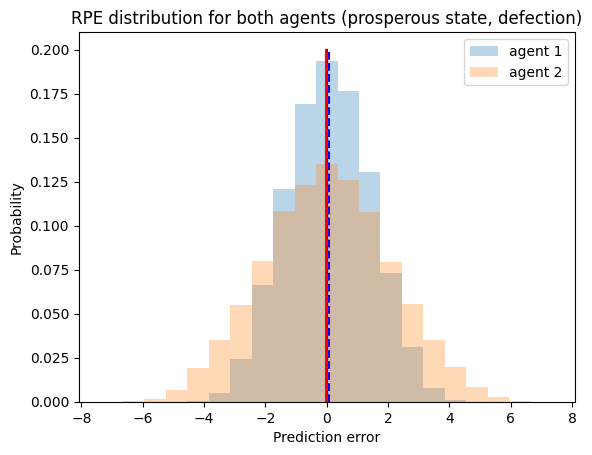

In [33]:
## Plot pred error distribution

i, s, a = 1, 1, 1

plt.bar(new_means, Disad[0, s, a, :], width=new_delta, alpha=0.3, label="agent 1")
plt.bar(new_means, Disad[1, s, a, :], width=new_delta, alpha=0.3, label="agent 2")
plt.plot([mae.RPEisa(Xisa)[0,s,a], mae.RPEisa(Xisa)[0,s,a]], [0, 0.2], c='b')
plt.plot([np.dot(new_means, Disad[0, s, a, :]), np.dot(new_means, Disad[0, s, a, :])], [0, 0.2], '--', c='b')
plt.plot([mae.RPEisa(Xisa)[1,s,a], mae.RPEisa(Xisa)[1,s,a]], [0, 0.2], c='r')
plt.plot([np.dot(new_means, Disad[1, s, a, :]), np.dot(new_means, Disad[1, s, a, :])], [0, 0.2], '--', c='r')
plt.title("RPE distribution for both agents (prosperous state, defection)")
plt.legend()

plt.ylabel("Probability")
plt.xlabel("Prediction error")

Text(0.5, 0, 'Prediction error')

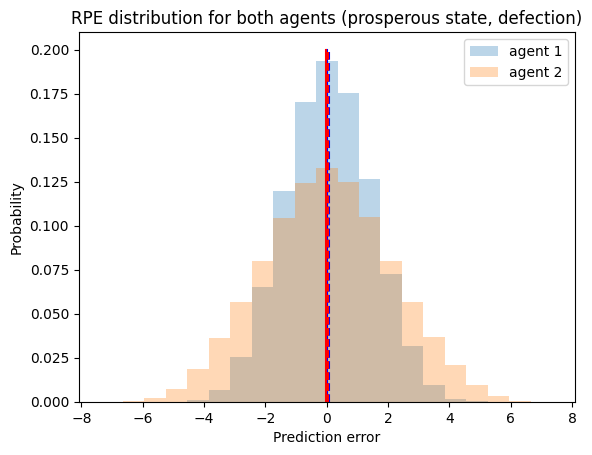

In [34]:
new_means = np.linspace(means.min() - means.max(), means.max() - means.min(), n_r)
new_delta = np.unique((new_means[1:] - new_means[:-1]).round(8))

## Plot pred error distribution for Disad_kron

i, s, a = 1, 1, 1

plt.bar(new_means, Disad_kron[0, s, a, :], width=new_delta, alpha=0.3, label="agent 1")
plt.bar(new_means, Disad_kron[1, s, a, :], width=new_delta, alpha=0.3, label="agent 2")
plt.plot([mae.RPEisa(Xisa)[0,s,a], mae.RPEisa(Xisa)[0,s,a]], [0, 0.2], c='b')
plt.plot([np.dot(new_means, Disad_kron[0, s, a, :]), np.dot(new_means, Disad_kron[0, s, a, :])], [0, 0.2], '--', c='b')
plt.plot([mae.RPEisa(Xisa)[1,s,a], mae.RPEisa(Xisa)[1,s,a]], [0, 0.2], c='r')
plt.plot([np.dot(new_means, Disad_kron[1, s, a, :]), np.dot(new_means, Disad_kron[1, s, a, :])], [0, 0.2], '--', c='r')
plt.title("RPE distribution for both agents (prosperous state, defection)")
plt.legend()

plt.ylabel("Probability")
plt.xlabel("Prediction error")

In [35]:
print("error agent 1 prosp def:", np.dot(new_means, Disad[0, 1, 1, :]) - mae.RPEisa(Xisa)[0, 1, 1])
print("error agent 2 prosp def:", np.dot(new_means, Disad[1, 1, 1, :]) - mae.RPEisa(Xisa)[1, 1, 1])
print("error agent 1 prosp coop:", np.dot(new_means, Disad[0, 1, 0, :]) - mae.RPEisa(Xisa)[0, 1, 0])
print("error agent 2 prosp coop:", np.dot(new_means, Disad[1, 1, 0, :]) - mae.RPEisa(Xisa)[1, 1, 0])
print("error agent 1 deg def:", np.dot(new_means, Disad[0, 0, 1, :]) - mae.RPEisa(Xisa)[0, 0, 1])
print("error agent 2 deg def:", np.dot(new_means, Disad[1, 0, 1, :]) - mae.RPEisa(Xisa)[1, 0, 1])
print("error agent 1 deg coop:", np.dot(new_means, Disad[0, 0, 0, :]) - mae.RPEisa(Xisa)[0, 0, 0])
print("error agent 2 deg coop:", np.dot(new_means, Disad[1, 0, 0, :]) - mae.RPEisa(Xisa)[1, 0, 0])

error agent 1 prosp def: 0.04366329
error agent 2 prosp def: 0.039932754
error agent 1 prosp coop: 0.0054007936
error agent 2 prosp coop: 0.016062804
error agent 1 deg def: -0.073207416
error agent 2 deg def: -0.07590203
error agent 1 deg coop: -0.08173489
error agent 2 deg coop: -0.09292268


In [36]:
print("error agent 1 prosp def:", np.dot(new_means, Disad_kron[0, 1, 1, :]) - mae.RPEisa(Xisa)[0, 1, 1])
print("error agent 2 prosp def:", np.dot(new_means, Disad_kron[1, 1, 1, :]) - mae.RPEisa(Xisa)[1, 1, 1])
print("error agent 1 prosp coop:", np.dot(new_means, Disad_kron[0, 1, 0, :]) - mae.RPEisa(Xisa)[0, 1, 0])
print("error agent 2 prosp coop:", np.dot(new_means, Disad_kron[1, 1, 0, :]) - mae.RPEisa(Xisa)[1, 1, 0])
print("error agent 1 deg def:", np.dot(new_means, Disad_kron[0, 0, 1, :]) - mae.RPEisa(Xisa)[0, 0, 1])
print("error agent 2 deg def:", np.dot(new_means, Disad_kron[1, 0, 1, :]) - mae.RPEisa(Xisa)[1, 0, 1])
print("error agent 1 deg coop:", np.dot(new_means, Disad_kron[0, 0, 0, :]) - mae.RPEisa(Xisa)[0, 0, 0])
print("error agent 2 deg coop:", np.dot(new_means, Disad_kron[1, 0, 0, :]) - mae.RPEisa(Xisa)[1, 0, 0])

error agent 1 prosp def: 0.042301238
error agent 2 prosp def: 0.053700242
error agent 1 prosp coop: 0.020921009
error agent 2 prosp coop: 0.021703385
error agent 1 deg def: -0.022532009
error agent 2 deg def: -0.03264804
error agent 1 deg coop: -0.033831388
error agent 2 deg coop: -0.050439775


In [37]:
print(np.mean(Disad[0, 1, 1, :]), np.std(Disad[0, 1, 1, :]))

0.047619041299097394 0.06641860404434916


In [38]:
print(np.mean(Disad_kron[0, 1, 1, :]), np.std(Disad_kron[0, 1, 1, :]))

0.0476190412990973 0.06595588787594896


In [39]:
print(np.mean(Disad[1, 1, 1, :]), np.std(Disad[1, 1, 1, :]))

0.0476190425462862 0.047461727229613025


In [40]:
print(np.mean(Disad_kron[1, 1, 1, :]), np.std(Disad_kron[1, 1, 1, :]))

0.04761904254628609 0.04672425692213494
